# 01 — Exploración de datos: Reconocimiento de Actividades Humanas (HAR)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/garcialvarez/HAR/blob/main/01_exploracion_datos.ipynb)

**Entrega 2 — Notebook 1 de 7.** Este notebook reproduce y amplía el análisis exploratorio de la
Entrega 1 ([`ENTREGA1.PDF`](ENTREGA1.PDF)): tamaño del dataset, distribución de clases, normalización
del vector de 561 características, forma de las señales inerciales crudas y separación de sujetos.
Además agrega tres análisis que anticipan las decisiones de la Entrega 2:

- cómo se ven las **señales crudas** de cada actividad (modalidad *tiempo*),
- cuántas ventanas aporta **cada sujeto** (relevante para la validación por sujeto),
- cómo se ven los **espectrogramas** de cada actividad (modalidad *tiempo-frecuencia*).

Dataset: [UCI HAR Dataset](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones)
(30 voluntarios, smartphone en la cintura, acelerómetro y giroscopio a 50 Hz, ventanas de 2.56 s).

> Reproducible en **Google Colab**: clona el repositorio, instala dependencias y descarga el dataset
> sin pasos manuales. **Entradas:** ninguna. **Salidas:** solo figuras y tablas en este notebook.

In [1]:
# --- Arranque (Colab o local): clona el repositorio si hace falta y entra en él ---
import os, subprocess

REPO_URL = "https://github.com/garcialvarez/HAR.git"

if not os.path.exists("src/data_loader.py"):      # en Colab: cwd = /content
    if not os.path.isdir("HAR"):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("HAR")

print("Directorio de trabajo:", os.getcwd())

Directorio de trabajo: c:\Users\GARCIA\Documents\HAR


In [2]:
# Instala las dependencias (en Colab casi todas ya vienen instaladas).
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


C:\Users\GARCIA\Documents\HAR\.venv\Scripts\python.exe: No module named pip


In [3]:
# Descarga y descomprime el UCI HAR Dataset (si no está ya en data/raw/).
import sys
sys.path.append("src")

from data_loader import download_dataset
download_dataset()

WindowsPath('C:/Users/GARCIA/Documents/HAR/data/raw/UCI_HAR_Dataset')

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from data_loader import ACTIVITY_NAMES, INERTIAL_SIGNALS, load_features, load_raw_signals
from preprocessing import FS, compute_stft, add_magnitudes

pd.set_option("display.width", 120)
plt.rcParams["figure.dpi"] = 100

# Carga el vector de 561 características ya extraídas por los autores del dataset.
X_train, y_train, subj_train = load_features("train")
X_test, y_test, subj_test = load_features("test")

print(f"X_train: {X_train.shape}  |  X_test: {X_test.shape}")

X_train: (7352, 561)  |  X_test: (2947, 561)


## 1. Tamaño del dataset

Reproduce la **Tabla 1** de la propuesta: el dataset viene particionado *subject-wise* por los autores
originales (70% de los sujetos para entrenamiento, 30% para prueba), lo que evita fuga de información
entre sujetos.

In [5]:
resumen = pd.DataFrame(
    {
        "Partición": ["Entrenamiento", "Prueba", "Total"],
        "# Sujetos": [
            subj_train.nunique(),
            subj_test.nunique(),
            pd.concat([subj_train, subj_test]).nunique(),
        ],
        "# Ventanas": [len(X_train), len(X_test), len(X_train) + len(X_test)],
        "# Features": [X_train.shape[1], X_test.shape[1], X_train.shape[1]],
    }
)
resumen

,Partición,# Sujetos,# Ventanas,# Features
0,Entrenamiento,21,7352,561
1,Prueba,9,2947,561
2,Total,30,10299,561


## 2. Distribución de clases

Reproduce la **Tabla 2** de la propuesta. El dataset está razonablemente balanceado
(ratio máx/mín ≈ 1.43 en train), por lo que *accuracy* es una métrica interpretable sin ajustes
adicionales.

In [6]:
def distribucion(y):
    counts = y.value_counts().reindex(ACTIVITY_NAMES.values())
    pct = (counts / counts.sum() * 100).round(1)
    return counts, pct


train_counts, train_pct = distribucion(y_train)
test_counts, test_pct = distribucion(y_test)

dist_df = pd.DataFrame(
    {"Train": train_counts, "Train %": train_pct, "Test": test_counts, "Test %": test_pct}
)
print(f"Ratio máx/mín (train): {train_counts.max() / train_counts.min():.2f}")
dist_df

Ratio máx/mín (train): 1.43


,Train,Train %,Test,Test %
activity_id,,,,
WALKING,1226,16.7,496,16.8
WALKING_UPSTAIRS,1073,14.6,471,16.0
WALKING_DOWNSTAIRS,986,13.4,420,14.3
SITTING,1286,17.5,491,16.7
STANDING,1374,18.7,532,18.1
LAYING,1407,19.1,537,18.2


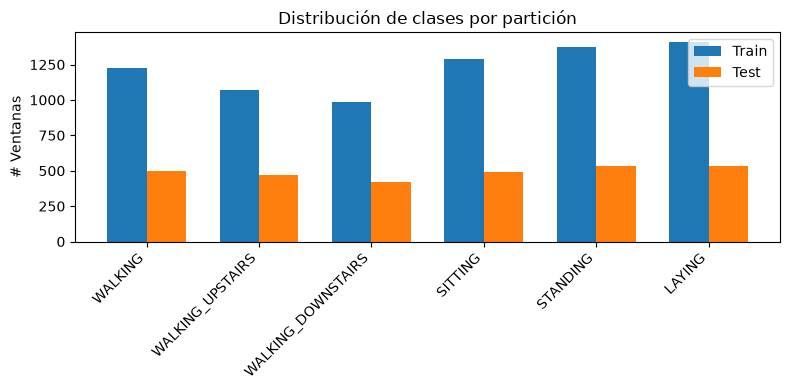

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(ACTIVITY_NAMES))
width = 0.35
ax.bar(x - width / 2, train_counts.values, width, label="Train")
ax.bar(x + width / 2, test_counts.values, width, label="Test")
ax.set_xticks(x)
ax.set_xticklabels(train_counts.index, rotation=45, ha="right")
ax.set_ylabel("# Ventanas")
ax.set_title("Distribución de clases por partición")
ax.legend()
fig.tight_layout()
plt.show()

## 3. Verificación de normalización del vector de 561 features

La propuesta afirma que las 561 características (dominio tiempo/frecuencia) ya vienen
normalizadas en el rango $[-1, 1]$. Lo verificamos directamente sobre los datos.

Valor mínimo global: -1.0000
Valor máximo global:  1.0000


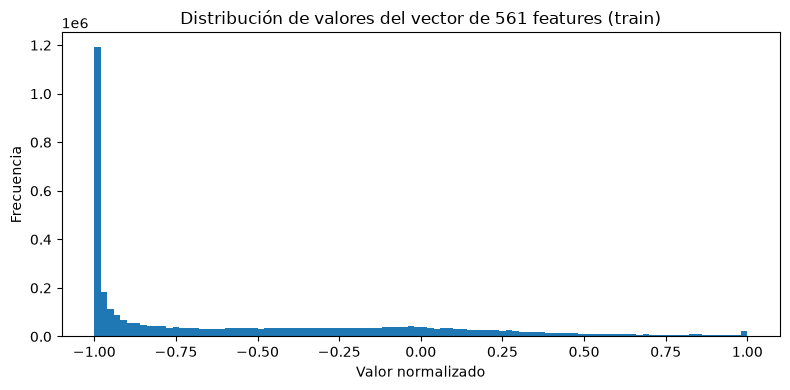

In [8]:
print(f"Valor mínimo global: {X_train.min().min(): .4f}")
print(f"Valor máximo global: {X_train.max().max(): .4f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(X_train.values.ravel(), bins=100)
ax.set_title("Distribución de valores del vector de 561 features (train)")
ax.set_xlabel("Valor normalizado")
ax.set_ylabel("Frecuencia")
fig.tight_layout()
plt.show()

## 4. Señales inerciales crudas

Además del vector de features, el dataset ofrece las señales crudas: 9 canales
(aceleración total y corporal en X/Y/Z, velocidad angular en X/Y/Z) × 128 pasos temporales por
ventana (2.56 s a 50 Hz). Estas son las señales que usarían modelos de deep learning
(CNN/RNN) en etapas posteriores del proyecto, en vez del vector de features ya calculado.

Forma de las señales crudas (train): (7352, 128, 9)  (ventanas, pasos, canales)
Canales disponibles: ['body_acc_x', 'body_acc_y', 'body_acc_z', 'body_gyro_x', 'body_gyro_y', 'body_gyro_z', 'total_acc_x', 'total_acc_y', 'total_acc_z']


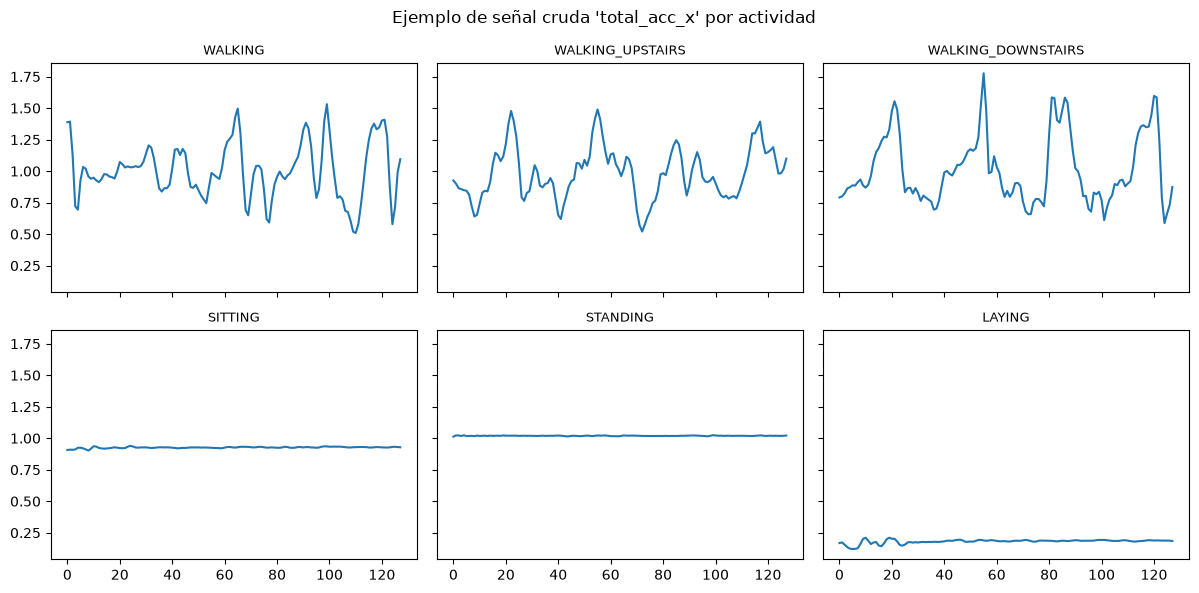

In [9]:
X_raw_train, y_raw_train, _ = load_raw_signals("train")
print(f"Forma de las señales crudas (train): {X_raw_train.shape}  (ventanas, pasos, canales)")
print(f"Canales disponibles: {INERTIAL_SIGNALS}")

channel_idx = INERTIAL_SIGNALS.index("total_acc_x")
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey=True)
for ax, act in zip(axes.ravel(), ACTIVITY_NAMES.values()):
    idx = y_raw_train[y_raw_train == act].index[0]
    ax.plot(X_raw_train[idx, :, channel_idx])
    ax.set_title(act, fontsize=9)
fig.suptitle("Ejemplo de señal cruda 'total_acc_x' por actividad")
fig.tight_layout()
plt.show()

## 5. Los 9 canales de una ventana, por actividad

Una ventana contiene tres sensores (aceleración total, aceleración corporal y giroscopio), cada uno con
sus ejes X/Y/Z. La **aceleración total** incluye la gravedad (≈ 1 g repartido entre los ejes según la
orientación del teléfono); la **aceleración corporal** es lo que queda al quitarla (filtro pasa-bajas de
0.3 Hz). Se muestra la ventana central de un sujeto (la primera ventana de cada registro tiene el
transitorio de ese filtro y no es representativa). Las actividades dinámicas (caminar, subir/bajar escaleras) tienen oscilaciones claras; las
estáticas (sentado, de pie, acostado) se distinguen casi solo por la **orientación** (la gravedad).

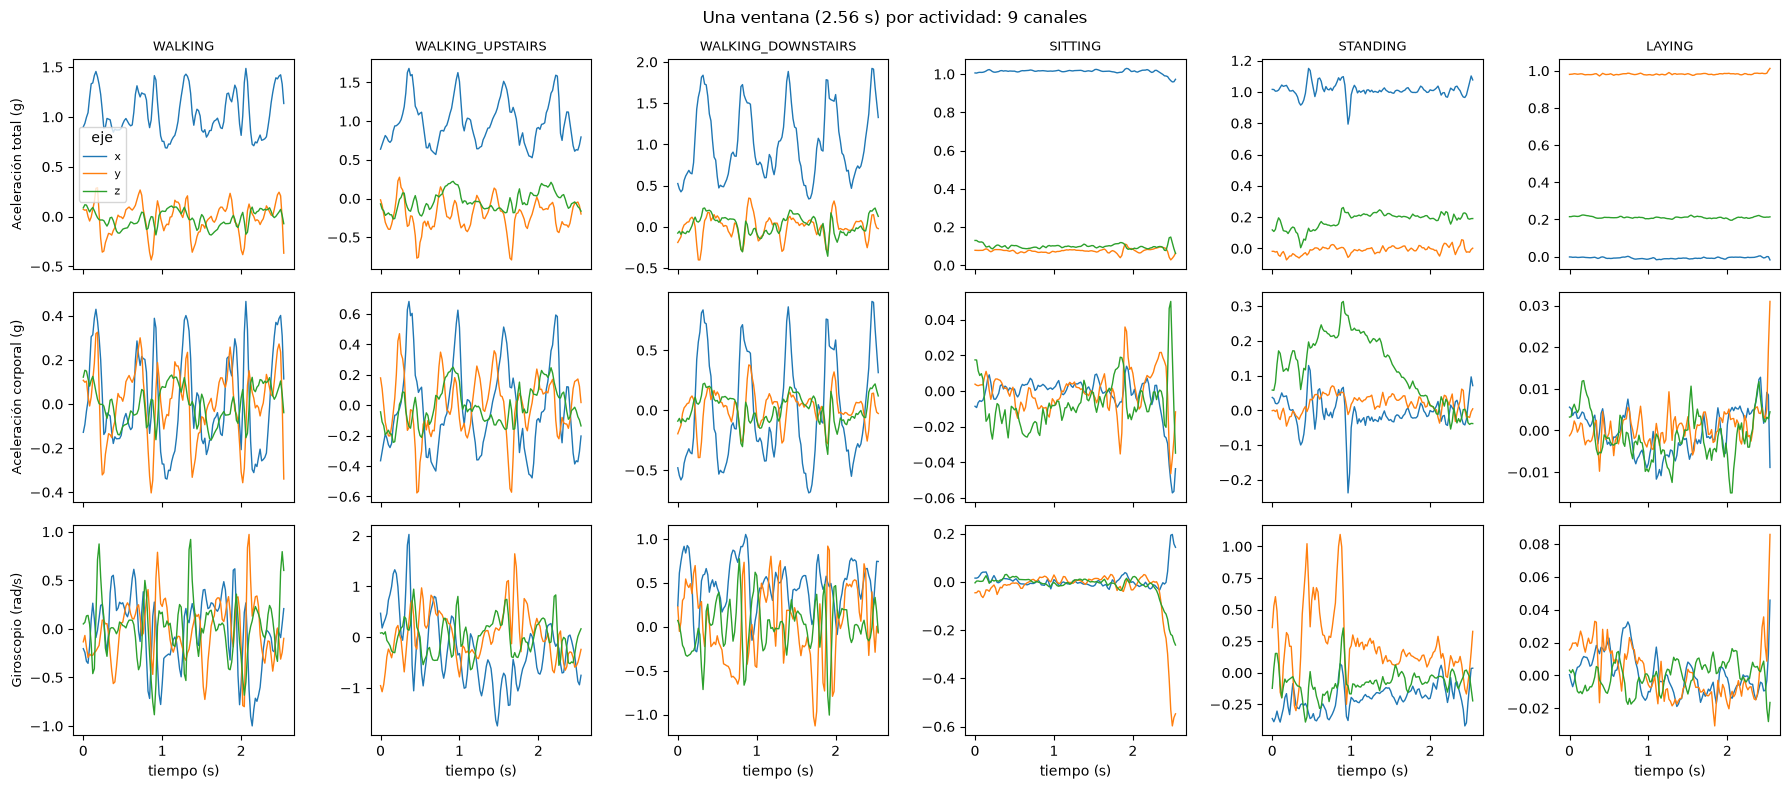

In [10]:
def ventana_ejemplo(act, sujeto=5):
    """Ventana central de un sujeto. Se evita la 1.ª ventana de cada registro: allí el filtro
    que separa la gravedad todavía está en su transitorio y body_acc no es representativa."""
    ids = np.where((y_raw_train.values == act) & (subj_train.values == sujeto))[0]
    return ids[len(ids) // 2]

t = np.arange(128) / FS
sensores = [("total_acc", "Aceleración total (g)"), ("body_acc", "Aceleración corporal (g)"), ("body_gyro", "Giroscopio (rad/s)")]
fig, axes = plt.subplots(3, 6, figsize=(18, 8), sharex=True)
for col, act in enumerate(ACTIVITY_NAMES.values()):
    idx = ventana_ejemplo(act)
    for row, (sensor, etiqueta) in enumerate(sensores):
        ax = axes[row, col]
        for eje in "xyz":
            ax.plot(t, X_raw_train[idx, :, INERTIAL_SIGNALS.index(f"{sensor}_{eje}")], label=eje, lw=1)
        if row == 0:
            ax.set_title(act, fontsize=9)
        if col == 0:
            ax.set_ylabel(etiqueta, fontsize=9)
        if row == 2:
            ax.set_xlabel("tiempo (s)")
axes[0, 0].legend(title="eje", fontsize=8)
fig.suptitle("Una ventana (2.56 s) por actividad: 9 canales")
fig.tight_layout()
plt.show()

## 6. Ventanas por sujeto y por clase

La validación por sujeto exige saber cuánto aporta cada voluntario: si unos pocos sujetos dominan, los
resultados de un fold dependen mucho de quién cae en él. Las ventanas se traslapan 50 %, así que las
ventanas consecutivas de un mismo sujeto son casi copias: por eso **no** se pueden repartir al azar
entre entrenamiento y prueba (se demuestra en el notebook 02).

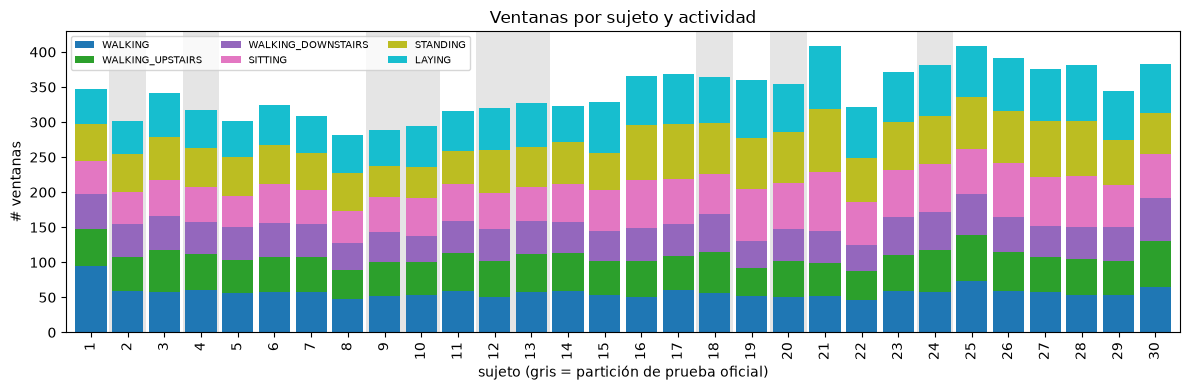

Ventanas por sujeto: min=281  mediana=342  max=409
Mínimo de ventanas de una clase en un sujeto: 36


In [11]:
subj_all = pd.concat([subj_train, subj_test], ignore_index=True)
y_all = pd.concat([y_train, y_test], ignore_index=True)
conteo = pd.crosstab(subj_all, y_all)[list(ACTIVITY_NAMES.values())]

fig, ax = plt.subplots(figsize=(12, 4))
conteo.plot(kind="bar", stacked=True, ax=ax, width=0.85, colormap="tab10")
for k, s in enumerate(conteo.index):
    if s in set(subj_test):
        ax.axvspan(k - 0.5, k + 0.5, color="grey", alpha=0.2, lw=0, zorder=0)
ax.set_xlabel("sujeto (gris = partición de prueba oficial)")
ax.set_ylabel("# ventanas")
ax.set_title("Ventanas por sujeto y actividad")
ax.legend(fontsize=7, ncol=3)
fig.tight_layout()
plt.show()

tot = conteo.sum(axis=1)
print(f"Ventanas por sujeto: min={tot.min()}  mediana={int(tot.median())}  max={tot.max()}")
print("Mínimo de ventanas de una clase en un sujeto:", int(conteo.values.min()))

## 7. Vista previa de la modalidad tiempo-frecuencia

Una alternativa a alimentar la serie directamente a la red es transformarla a un **espectrograma**
(STFT): una imagen frecuencia × tiempo. Abajo, la magnitud de la aceleración corporal de una ventana por
actividad. Las actividades dinámicas concentran la energía en bajas frecuencias (cadencia del paso, < 3 Hz) con
armónicos hasta ~10 Hz; las estáticas casi no tienen energía. En el notebook 02 se comparan dos resoluciones y en el 06 se
entrena una CNN 2D sobre estas imágenes.

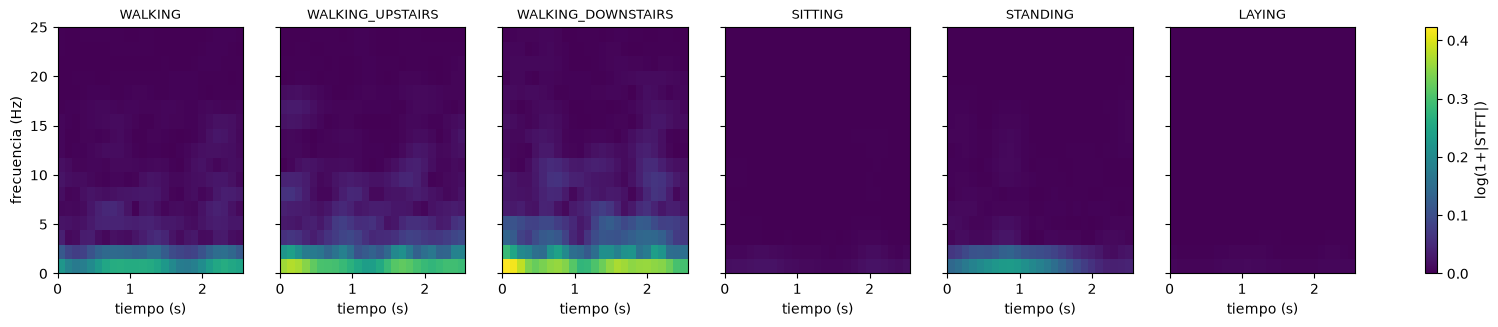

Forma del espectrograma por canal: (17, 25) (frecuencias × tiempos)


In [12]:
idxs = [ventana_ejemplo(act) for act in ACTIVITY_NAMES.values()]
mag_body = add_magnitudes(X_raw_train[idxs])[..., [9]]          # |body_acc|, (6, 128, 1)
S = compute_stft(mag_body, nperseg=32)                          # (6, F, T', 1)
vmax = S.max()

fig, axes = plt.subplots(1, 6, figsize=(18, 3.2), sharey=True)
for ax, s, act in zip(axes, S, ACTIVITY_NAMES.values()):
    im = ax.imshow(s[..., 0], origin="lower", aspect="auto", vmin=0, vmax=vmax,
                   extent=[0, 2.56, 0, FS / 2], cmap="viridis")
    ax.set_title(act, fontsize=9)
    ax.set_xlabel("tiempo (s)")
axes[0].set_ylabel("frecuencia (Hz)")
fig.colorbar(im, ax=axes, label="log(1+|STFT|)", fraction=0.02)
plt.show()
print("Forma del espectrograma por canal:", S.shape[1:3], "(frecuencias × tiempos)")

## 8. Separación de sujetos entre train y test

Confirmamos que la partición es *subject-wise*: ningún sujeto aparece en ambas particiones,
lo que evita fuga de información entre entrenamiento y prueba.

In [13]:
sujetos_train = sorted(int(s) for s in subj_train.unique())
sujetos_test = sorted(int(s) for s in subj_test.unique())
overlap = set(sujetos_train) & set(sujetos_test)

print(f"Sujetos train ({len(sujetos_train)}): {sujetos_train}")
print(f"Sujetos test  ({len(sujetos_test)}): {sujetos_test}")
print(f"Sujetos en ambas particiones: {sorted(overlap) if overlap else 'ninguno'}")

assert len(overlap) == 0, "Se esperaba que train y test no compartieran sujetos"

Sujetos train (21): [1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 17, 19, 21, 22, 23, 25, 26, 27, 28, 29, 30]
Sujetos test  (9): [2, 4, 9, 10, 12, 13, 18, 20, 24]
Sujetos en ambas particiones: ninguno


## Conclusiones

In [14]:
n_tr, n_te = len(X_train), len(X_test)
ratio = y_train.value_counts().max() / y_train.value_counts().min()
print(f"- {n_tr + n_te:,} ventanas ({n_tr:,} train / {n_te:,} test) de {X_train.shape[1]} features, "
      f"de {subj_all.nunique()} sujetos particionados por sujeto ({subj_train.nunique()} / {subj_test.nunique()}), sin solapamiento.")
print(f"- Clases balanceadas: ratio máx/mín = {ratio:.2f} en train, así que accuracy es interpretable; se complementa con F1 por clase.")
print(f"- Las 561 features están en [{X_train.min().min():.0f}, {X_train.max().max():.0f}].")
print(f"- Señales crudas: {X_raw_train.shape[1:]} por ventana (pasos × canales), listas para CNN/RNN.")
print(f"- Cada sujeto aporta entre {tot.min()} y {tot.max()} ventanas: la validación debe agruparse por sujeto.")
print(f"- Las actividades dinámicas y estáticas se separan bien en el espectrograma; se explorará en los notebooks 02 y 06.")

- 10,299 ventanas (7,352 train / 2,947 test) de 561 features, de 30 sujetos particionados por sujeto (21 / 9), sin solapamiento.
- Clases balanceadas: ratio máx/mín = 1.43 en train, así que accuracy es interpretable; se complementa con F1 por clase.
- Las 561 features están en [-1, 1].
- Señales crudas: (128, 9) por ventana (pasos × canales), listas para CNN/RNN.
- Cada sujeto aporta entre 281 y 409 ventanas: la validación debe agruparse por sujeto.
- Las actividades dinámicas y estáticas se separan bien en el espectrograma; se explorará en los notebooks 02 y 06.


Siguiente: [`02_preprocesado.ipynb`](02_preprocesado.ipynb) — normalización, integración numérica de la
aceleración, espectrogramas y demostración de la fuga de información entre ventanas del mismo sujeto.